In [1]:
# Cài thư viện ngay ở cell code đầu tiên, bằng đúng Python của kernel.
import sys, subprocess
from pathlib import Path
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / 'requirements.txt').is_file()), None)

# Vision Transformer: kiến trúc và thực nghiệm

**ViT-B/16 · ImageNet-1K · 15 ảnh · inference pretrained**

Ảnh là lưới hai chiều. ViT chuyển các vùng ảnh thành chuỗi vector, thêm token CLS
rồi dùng self-attention trao đổi thông tin giữa các vị trí. Notebook này theo dõi
tensor thật trong mô hình, hiển thị Top-5 và đo thay đổi dự đoán khi che vùng.
Mọi hình và bảng hiển thị đều có bản PNG trong `outputs`; bảng số có thêm CSV.

Dữ liệu gồm 15 ảnh được chọn cố định từ validation của Imagenette trước khi suy luận.
Đây là tập minh họa nhỏ, có nguồn từ ImageNet, **không phải benchmark độc lập**.
Không huấn luyện hoặc fine-tune trong thực nghiệm này.

In [2]:
import os, json, time, random, platform, hashlib, math, textwrap
from datetime import datetime, timezone, timedelta
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import torch, torchvision
from torch.nn import functional as F
from torchvision.models import vit_b_16, ViT_B_16_Weights
from torchvision.transforms import functional as TF
from PIL import Image
from IPython.display import display, Markdown

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
torch.set_num_threads(min(4, os.cpu_count() or 1))
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
if DEVICE.type == 'cuda':
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
OUT = ROOT / 'outputs'
FIG = OUT / 'figures'
TAB = OUT / 'tables'
for folder in [OUT, FIG, TAB, OUT / 'processed', OUT / 'occluded']:
    folder.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 11,
                     'axes.spines.top': False, 'axes.spines.right': False,
                     'figure.facecolor': 'white', 'axes.facecolor': 'white',
                     'savefig.dpi': 180})
BLUE, ORANGE, PURPLE = '#2563EB', '#F97316', '#7C3AED'
figure_paths, table_paths, checks = [], [], {}

def save_figure(fig, name):
    path = FIG / f'{name}.png'
    fig.savefig(path, bbox_inches='tight', facecolor=fig.get_facecolor())
    figure_paths.append(path.relative_to(ROOT).as_posix())
    plt.show()
    plt.close(fig)
    return path

def export_table(df, name, title=None, rows_per_page=18, _part=False):
    """Paginate both rows and columns, keeping identifier columns on wide tables."""
    if not _part:
        df.to_csv(OUT / f'{name}.csv', index=False, encoding='utf-8-sig')
        display(df)
    if len(df.columns) > 7:
        fixed = list(df.columns[:2])
        rest = list(df.columns[2:])
        for i in range(0, len(rest), 5):
            export_table(df[fixed + rest[i:i+5]], f'{name}_c{i//5+1:02d}',
                         f'{title or name} / nhóm cột {i//5+1}', rows_per_page, _part=True)
        return
    for start in range(0, max(1, len(df)), rows_per_page):
        page = df.iloc[start:start + rows_per_page].copy()
        for col in page.columns:
            page[col] = page[col].map(lambda v: f'{v:.4f}' if isinstance(v, (float, np.floating)) else str(v))
            page[col] = page[col].map(lambda v: '\n'.join(textwrap.wrap(v, 28)) if len(v) > 30 else v)
        heights = [max(str(v).count('\n') + 1 for v in row) for row in page.values]
        height = 1.2 + sum(max(0.42, h * 0.22) for h in heights)
        labels=['\n'.join(textwrap.wrap(str(c).replace('_',' '), 18)) for c in page.columns]
        header_units=max(2.4, max(label.count('\n')+1 for label in labels)*1.3)
        height += .2 * (header_units - 2.4)
        fig, ax = plt.subplots(figsize=(max(8, len(page.columns) * 2.6), height))
        ax.axis('off')
        table = ax.table(cellText=page.values, colLabels=labels,
                         loc='center', cellLoc='left', bbox=[0, 0, 1, .91])
        table.auto_set_font_size(False); table.set_fontsize(9)
        total_units = sum(max(2, h) for h in heights) + header_units
        for (r, c), cell in table.get_celld().items():
            cell.set_edgecolor('#E2E8F0')
            cell.set_height((header_units if r == 0 else max(2, heights[r-1])) / total_units * .91)
            if r == 0:
                cell.set_facecolor('#0F172A'); cell.set_text_props(color='white', weight='bold')
            else:
                cell.set_facecolor('#EFF6FF' if r % 2 else '#FFFFFF')
        suffix = f'_{start // rows_per_page + 1:02d}'
        ax.set_title((title or name) + (f' ({start+1}–{start+len(page)})' if len(df)>rows_per_page else ''), loc='left', pad=16, fontsize=14, weight='bold')
        path = TAB / f'{name}{suffix}.png'
        fig.savefig(path, bbox_inches='tight')
        table_paths.append(path.relative_to(ROOT).as_posix())
        plt.close(fig)

started = time.perf_counter()
print(f'Thiết bị: {DEVICE}. PyTorch {torch.__version__}, TorchVision {torchvision.__version__}')

Thiết bị: cpu. PyTorch 2.14.1+cpu, TorchVision 0.29.2+cpu


## 1. Dữ liệu và nguồn ảnh
Imagenette cung cấp 10 lớp con của ImageNet. Chọn hai tên tệp đầu tiên (sắp xếp)
ở 5 lớp đầu và một tên ở 5 lớp còn lại: 15 ảnh. Nhãn lấy từ thư mục của bộ dữ liệu,
không lấy từ dự đoán mô hình. Ảnh nguồn đã có cạnh ngắn 160 px, nên phép resize
lên 256 có thể làm mất chi tiết so với ảnh gốc độ phân giải cao.
Manifest lưu tên tệp gốc, SHA256 và URL tải. Quyền ảnh thuộc tác giả gốc;
giấy phép kho mã Imagenette không xác lập giấy phép riêng cho từng ảnh.

,image_id,class_id,class_name,split
0,n01440764_01,0,tench,imagenette validation
1,n01440764_02,0,tench,imagenette validation
2,n02102040_01,217,English springer,imagenette validation
3,n02102040_02,217,English springer,imagenette validation
4,n02979186_01,482,cassette player,imagenette validation
5,n02979186_02,482,cassette player,imagenette validation
6,n03000684_01,491,chain saw,imagenette validation
7,n03000684_02,491,chain saw,imagenette validation
8,n03028079_01,497,church,imagenette validation
9,n03028079_02,497,church,imagenette validation


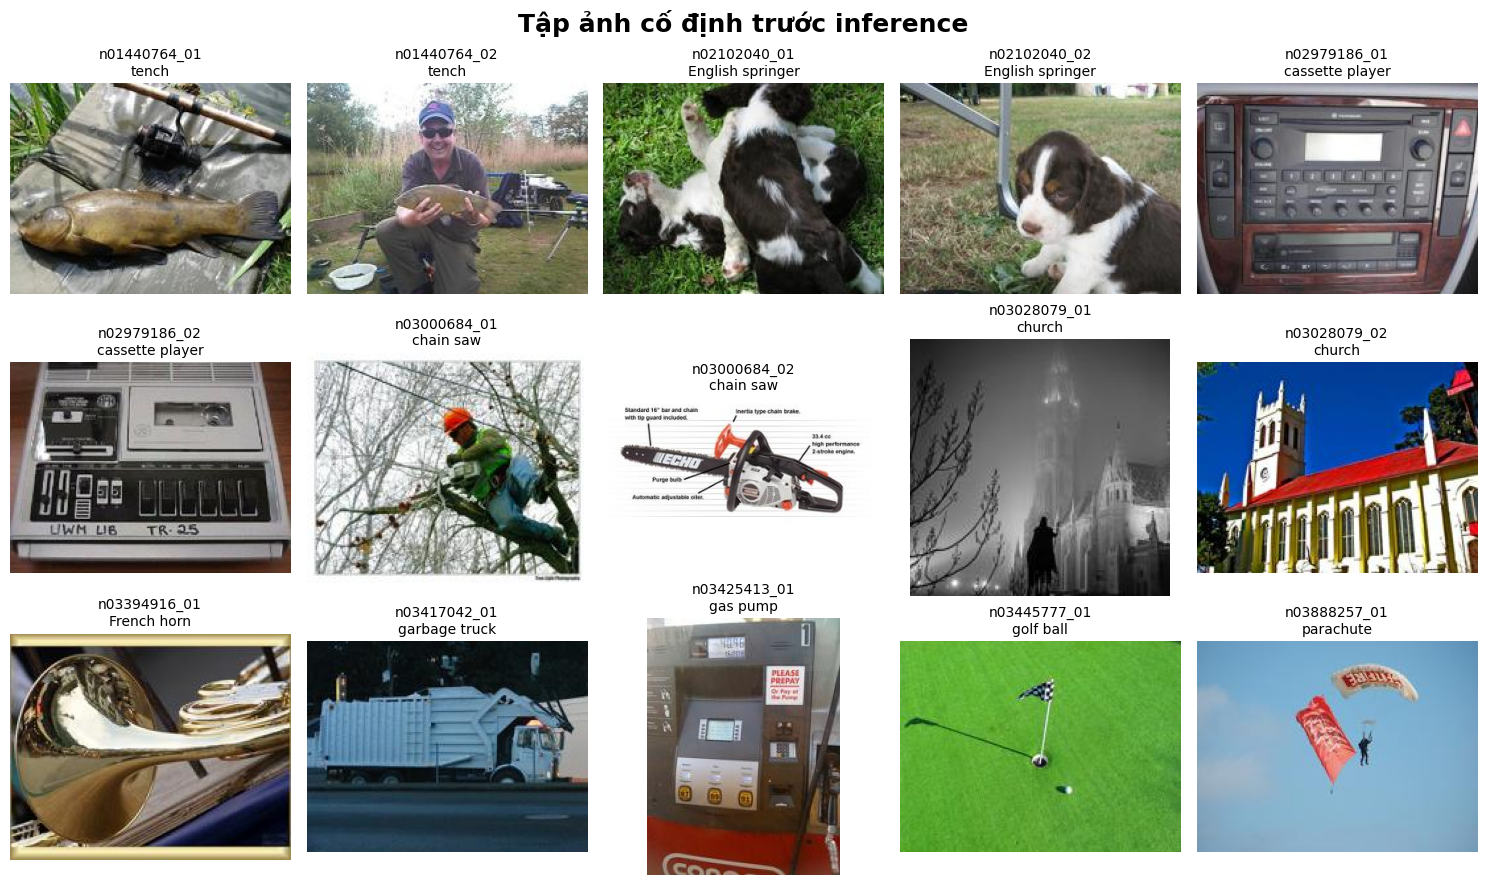

WindowsPath('d:/Github/Vision_Transfomer/outputs/figures/dataset_gallery.png')

In [3]:
# Tự chuẩn bị dữ liệu nếu bản sao dự án chưa chứa ảnh/checkpoint.
if not (ROOT / 'data/manifest.csv').exists() or not (ROOT / 'data/checkpoints/vit_b_16-c867db91.pth').exists():
    subprocess.check_call([sys.executable, str(ROOT / 'scripts/prepare_data.py')])
manifest = pd.read_csv(ROOT / 'data/manifest.csv')
assert len(manifest) == 15 and manifest.image_id.is_unique
weights = ViT_B_16_Weights.IMAGENET1K_V1
categories = weights.meta['categories']
images = {}
for row in manifest.itertuples():
    path = ROOT / row.relative_path
    assert hashlib.sha256(path.read_bytes()).hexdigest() == row.sha256
    assert categories[row.class_id] == row.class_name
    with Image.open(path) as im:
        images[row.image_id] = im.convert('RGB')
checks['manifest_and_image_hashes'] = True
export_table(manifest[['image_id', 'class_id', 'class_name', 'split']], 'dataset_summary', '15 ảnh và nhãn ImageNet')
fig, axes = plt.subplots(3, 5, figsize=(15, 9))
for ax, row in zip(axes.flat, manifest.itertuples()):
    ax.imshow(images[row.image_id]); ax.axis('off')
    ax.set_title(f'{row.image_id}\n{row.class_name}', fontsize=10)
fig.suptitle('Tập ảnh cố định trước inference', fontsize=18, weight='bold')
fig.tight_layout()
save_figure(fig, 'dataset_gallery')

## 2. Checkpoint và tiền xử lý
Dùng `ViT_B_16_Weights.IMAGENET1K_V1` và chính `weights.transforms()`:
resize cạnh ngắn 256, center crop 224, chuẩn hóa mean/std ImageNet.
`model.eval()` tắt dropout; `torch.inference_mode()` tắt theo dõi gradient.
Trọng số của demo được huấn luyện trên ImageNet-1K theo recipe của TorchVision,
không đồng nhất với các checkpoint pretraining quy mô lớn trong bài báo ViT.

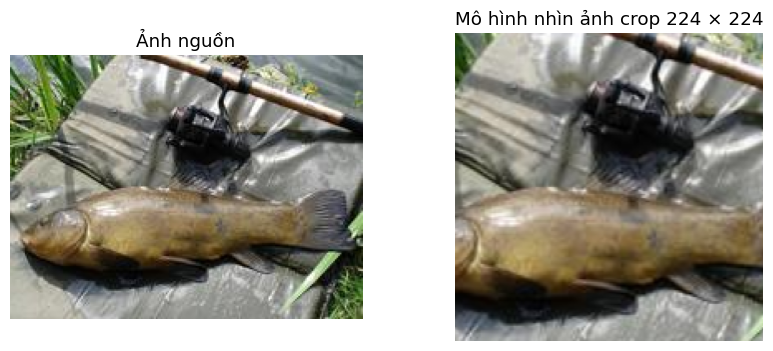

ImageClassification(
    crop_size=[224]
    resize_size=[256]
    mean=[0.485, 0.456, 0.406]
    std=[0.229, 0.224, 0.225]
    interpolation=InterpolationMode.BILINEAR
)
Số tham số: 86,567,656


In [4]:
checkpoint = ROOT / 'data/checkpoints/vit_b_16-c867db91.pth'
checkpoint_hash = hashlib.sha256(checkpoint.read_bytes()).hexdigest()
assert checkpoint_hash.startswith('c867db91')
model = vit_b_16(weights=None)
model.load_state_dict(torch.load(checkpoint, map_location='cpu', weights_only=True), strict=True)
model = model.to(DEVICE).eval()
transform = weights.transforms()
tensors = {key: transform(im) for key, im in images.items()}
mean = torch.tensor(transform.mean).view(3,1,1)
std = torch.tensor(transform.std).view(3,1,1)
def unnormalize(tensor):
    return (tensor.detach().cpu() * std + mean).clamp(0, 1).permute(1,2,0).numpy()
def save_rgb(tensor, path):
    Image.fromarray(np.round(unnormalize(tensor) * 255).astype(np.uint8)).save(path)
for key, tensor in tensors.items():
    assert tensor.shape == (3,224,224)
    save_rgb(tensor, OUT / 'processed' / f'{key}.png')
first_id = manifest.iloc[0].image_id
fig, axes = plt.subplots(1,2,figsize=(10,4))
axes[0].imshow(images[first_id]); axes[0].set_title('Ảnh nguồn')
axes[1].imshow(unnormalize(tensors[first_id])); axes[1].set_title('Mô hình nhìn ảnh crop 224 × 224')
for ax in axes: ax.axis('off')
save_figure(fig, 'preprocessing')
print(transform)
print(f'Số tham số: {sum(p.numel() for p in model.parameters()):,}')

## 3. Patch embedding, CLS và kích thước tensor
Với ảnh $224\times224\times3$ và patch $16\times16$, số patch là
$N=(224/16)^2=196$. Một patch flatten có $16\times16\times3=768$ phần tử.
Linear projection dùng chung ánh xạ sang $D=768$. Hai chiều bằng nhau trong cấu hình
này nhưng phép chiếu vẫn có trọng số học được.

`Conv2d(3,768,kernel_size=16,stride=16)` tương đương unfold + linear khi sắp xếp
và trọng số khớp nhau. **Ghép** CLS làm chuỗi dài 197. **Cộng** positional embedding
giữ nguyên độ dài 197. Encoder gồm 12 block Pre-LN:
Positional embedding cung cấp vị trí cho token vì self-attention thuần không tự
biết thứ tự không gian. CLS học cách tổng hợp thông tin phục vụ phân loại.
$u=x+MSA(LN(x))$, $z=u+MLP(LN(u))$. Final LayerNorm nằm sau chuỗi encoder.

,Bước,Kỳ vọng,Quan sát,Khớp
0,Ảnh NCHW,"(1, 3, 224, 224)","(1, 3, 224, 224)",True
1,Flatten patch,"(1, 196, 768)","(1, 196, 768)",True
2,Conv projection,"(1, 768, 14, 14)","(1, 768, 14, 14)",True
3,Patch embedding,"(1, 196, 768)","(1, 196, 768)",True
4,Ghép CLS,"(1, 197, 768)","(1, 197, 768)",True
5,Cộng vị trí,"(1, 197, 768)","(1, 197, 768)",True
6,Encoder 01,"(1, 197, 768)","(1, 197, 768)",True
7,Encoder 02,"(1, 197, 768)","(1, 197, 768)",True
8,Encoder 03,"(1, 197, 768)","(1, 197, 768)",True
9,Encoder 04,"(1, 197, 768)","(1, 197, 768)",True


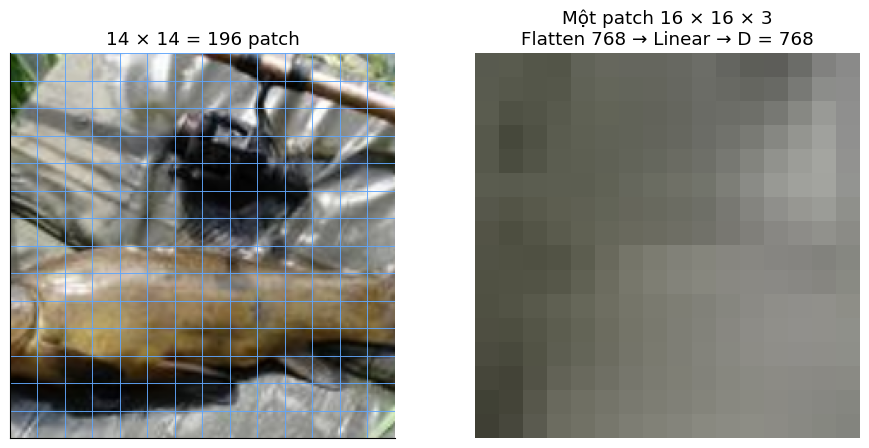

WindowsPath('d:/Github/Vision_Transfomer/outputs/figures/patch_grid.png')

In [5]:
x = tensors[first_id].unsqueeze(0).to(DEVICE)
trace = []
def record(name, tensor, expected):
    actual = tuple(tensor.shape)
    trace.append({'Bước':name,'Kỳ vọng':str(expected),'Quan sát':str(actual),'Khớp':actual == expected})
    assert actual == expected, (name, actual, expected)
with torch.inference_mode():
    record('Ảnh NCHW', x, (1,3,224,224))
    flat = F.unfold(x,kernel_size=16,stride=16).transpose(1,2)
    record('Flatten patch', flat, (1,196,768))
    conv = model.conv_proj(x)
    record('Conv projection',conv,(1,768,14,14))
    tokens = conv.flatten(2).transpose(1,2)
    linear = F.linear(flat,model.conv_proj.weight.flatten(1),model.conv_proj.bias)
    torch.testing.assert_close(tokens,linear,rtol=1e-4,atol=1e-5)
    record('Patch embedding',tokens,(1,196,768))
    z = torch.cat([model.class_token.expand(1,-1,-1),tokens],dim=1)
    record('Ghép CLS',z,(1,197,768))
    z = model.encoder.dropout(z + model.encoder.pos_embedding)
    record('Cộng vị trí',z,(1,197,768))
    for i, block in enumerate(model.encoder.layers):
        if i == 11:
            qkv = block.ln_1(z)
            _, attention = block.self_attention(qkv,qkv,qkv,need_weights=True,average_attn_weights=False)
        z = block(z)
        record(f'Encoder {i+1:02}',z,(1,197,768))
    z = model.encoder.ln(z)
    record('Final LayerNorm',z,(1,197,768))
    cls = z[:,0]
    record('Lấy CLS',cls,(1,768))
    traced_logits = model.heads(cls)
    record('Classification head',traced_logits,(1,1000))
    torch.testing.assert_close(traced_logits,model(x),rtol=1e-4,atol=1e-5)
checks['projection_equivalence'] = True
checks['trace_matches_forward'] = True
export_table(pd.DataFrame(trace),'tensor_shapes','Tensor thực tế qua ViT-B/16',rows_per_page=12)
fig, axes = plt.subplots(1,2,figsize=(11,5),gridspec_kw={'width_ratios':[1,1]})
axes[0].imshow(unnormalize(tensors[first_id])); axes[0].set_xticks(np.arange(-.5,224,16)); axes[0].set_yticks(np.arange(-.5,224,16))
axes[0].grid(color='#60A5FA',linewidth=.65); axes[0].tick_params(labelbottom=False,labelleft=False,length=0)
axes[0].set_title('14 × 14 = 196 patch')
axes[1].imshow(unnormalize(tensors[first_id])[80:96,80:96],interpolation='nearest'); axes[1].axis('off')
axes[1].set_title('Một patch 16 × 16 × 3\nFlatten 768 → Linear → D = 768')
save_figure(fig,'patch_grid')

## 4. Self-attention và patch size
Với 12 head, mỗi head có $d_k=768/12=64$.
$Q=ZW_Q$, $K=ZW_K$, $V=ZW_V$,
$A=softmax(QK^T/\sqrt{d_k})$, đầu ra mỗi head là $AV$.
Attention encoder không dùng causal mask. Mỗi hàng trong A là phân phối trọng số
của một query trên các key. Không gán sẵn mỗi head cho một ý nghĩa như màu hoặc cạnh.

Hình dưới lấy attention thật tại encoder cuối. Bản đồ CLS trung bình 12 head
chỉ hiển thị 196 key patch (bỏ cột CLS), không phải attention rollout hay bản đồ nhân quả.
**Attention không tự động giải thích đầy đủ quyết định của mô hình.**

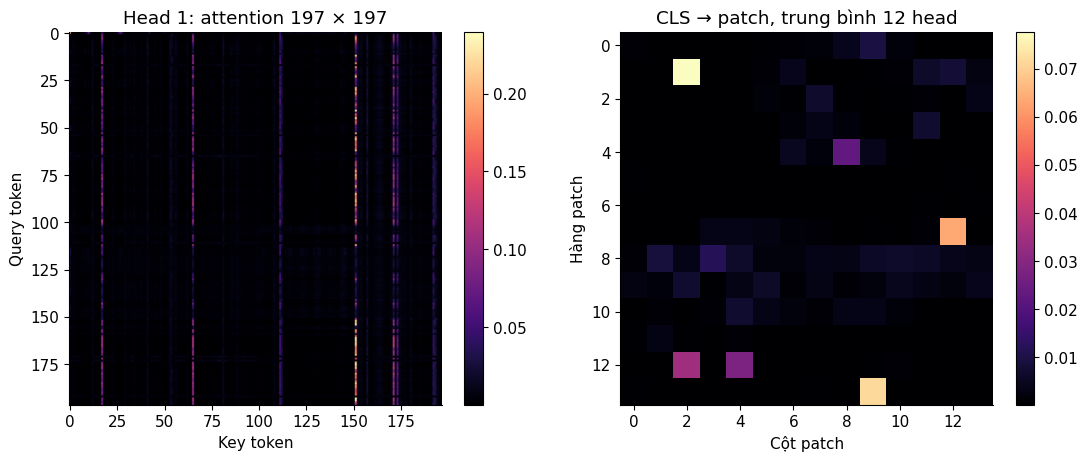

,Patch P,N patch,L gồm CLS,L² / head,Tỷ lệ so với P16
0,32,49,50,2500,0.064418
1,16,196,197,38809,1.000000
2,8,784,785,616225,15.878404


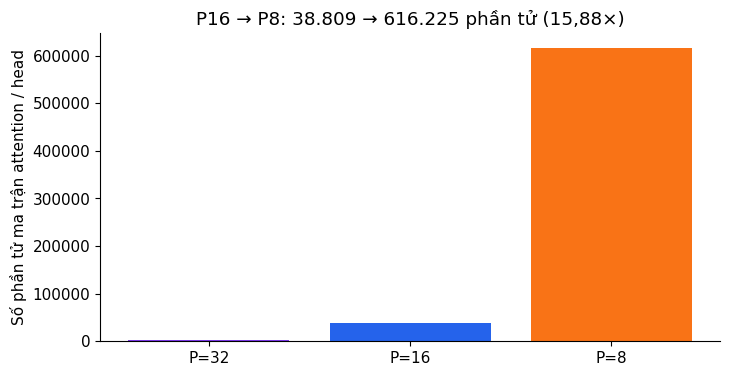

WindowsPath('d:/Github/Vision_Transfomer/outputs/figures/patch_complexity.png')

In [6]:
a = attention[0].cpu().numpy()
assert a.shape == (12,197,197)
np.testing.assert_allclose(a.sum(axis=-1),1,atol=1e-5)
np.save(OUT / 'last_layer_attention.npy',a)
fig, axes = plt.subplots(1,2,figsize=(11,4.5),constrained_layout=True)
im = axes[0].imshow(a[0],cmap='magma',aspect='equal')
axes[0].set(title='Head 1: attention 197 × 197',xlabel='Key token',ylabel='Query token')
fig.colorbar(im,ax=axes[0],fraction=.046)
cls_attention = a[:,0,1:].mean(0).reshape(14,14)
im = axes[1].imshow(cls_attention,cmap='magma',interpolation='nearest')
axes[1].set(title='CLS → patch, trung bình 12 head',xlabel='Cột patch',ylabel='Hàng patch')
fig.colorbar(im,ax=axes[1],fraction=.046)
save_figure(fig,'attention_actual')
complexity = pd.DataFrame([{'Patch P':p,'N patch':(224//p)**2,'L gồm CLS':(224//p)**2+1,
                            'L² / head':((224//p)**2+1)**2,
                            'Tỷ lệ so với P16':(((224//p)**2+1)/197)**2} for p in [32,16,8]])
export_table(complexity,'patch_complexity','Chi phí attention theo lý thuyết')
fig, ax = plt.subplots(figsize=(8,4))
ax.bar(['P=32','P=16','P=8'],complexity['L² / head'],color=[PURPLE,BLUE,ORANGE])
ax.set(ylabel='Số phần tử ma trận attention / head',title='P16 → P8: 38.809 → 616.225 phần tử (15,88×)')
ax.ticklabel_format(axis='y',style='plain')
save_figure(fig,'patch_complexity')

Đây là phép tính lý thuyết khi giữ kích thước ảnh và D cố định. P16 sang P8 làm
số patch tăng 4 lần, phần attention bậc hai tăng khoảng 15,88 lần khi tính CLS.
**Không suy ra thời gian toàn mô hình tăng 15,88 lần.** MLP và các phép chiếu còn
phụ thuộc L; kernel ảnh hưởng thời gian và bộ nhớ. Notebook không sửa patch size
của checkpoint B/16 để chạy ví dụ P8.

## 5. Classification head và huấn luyện
Sau final LN, CLS có 768 chiều. Head tuyến tính tạo 1.000 logits.
Huấn luyện tối ưu cross-entropy trên **logits** với nhãn lớp, ví dụ
`F.cross_entropy(logits, labels)`, rồi backward và cập nhật tham số.
Khi inference, softmax phục vụ hiển thị xác suất và Top-5.
Pretraining học từ tập lớn; fine-tuning tiếp tục cập nhật trên tác vụ đích,
có thể thay head theo số lớp. Thực nghiệm dưới đây chỉ inference.

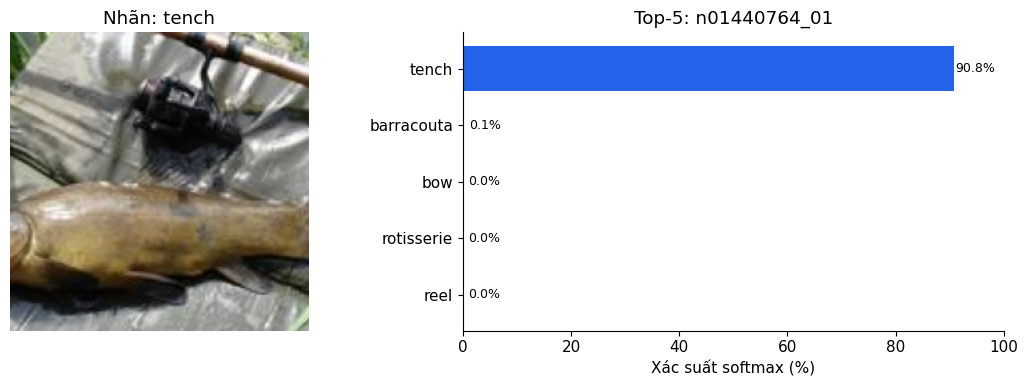

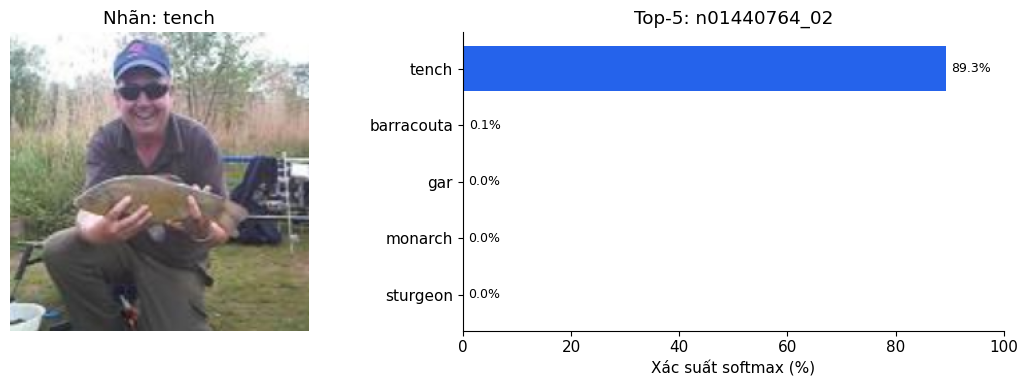

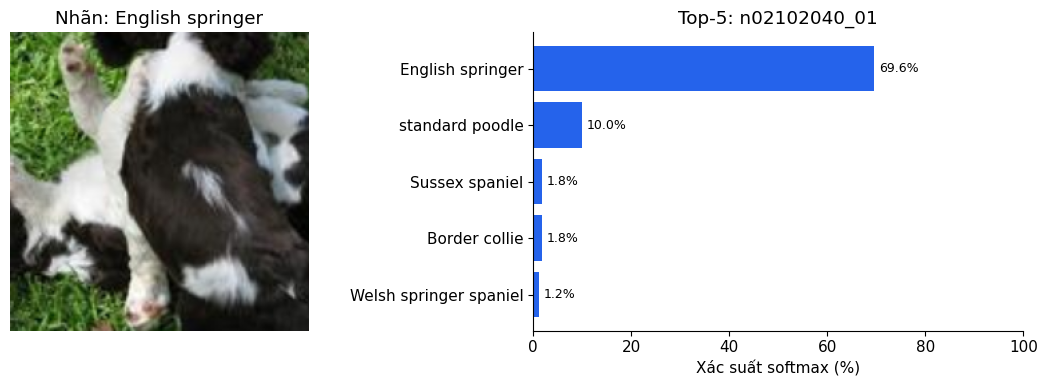

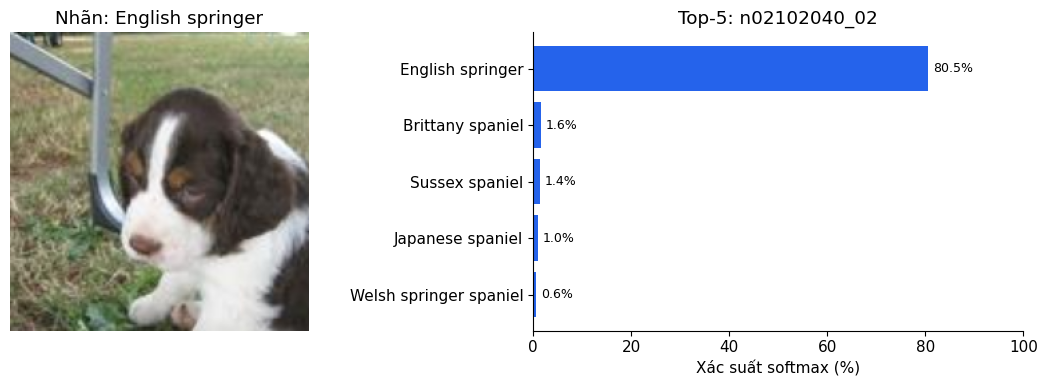

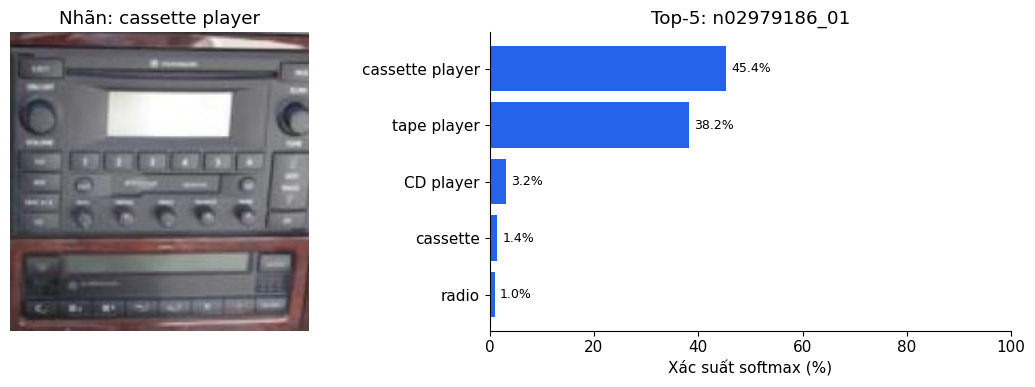

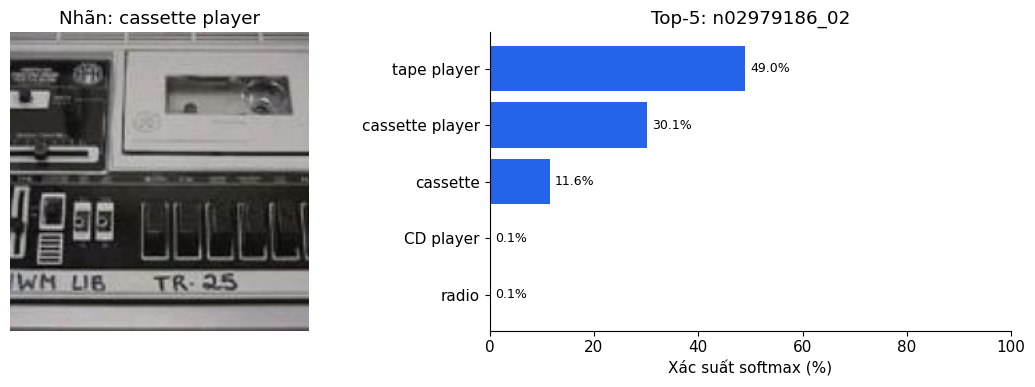

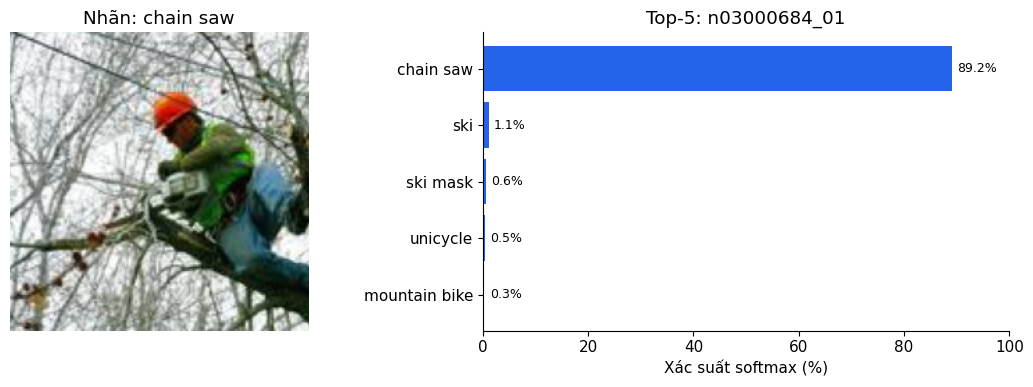

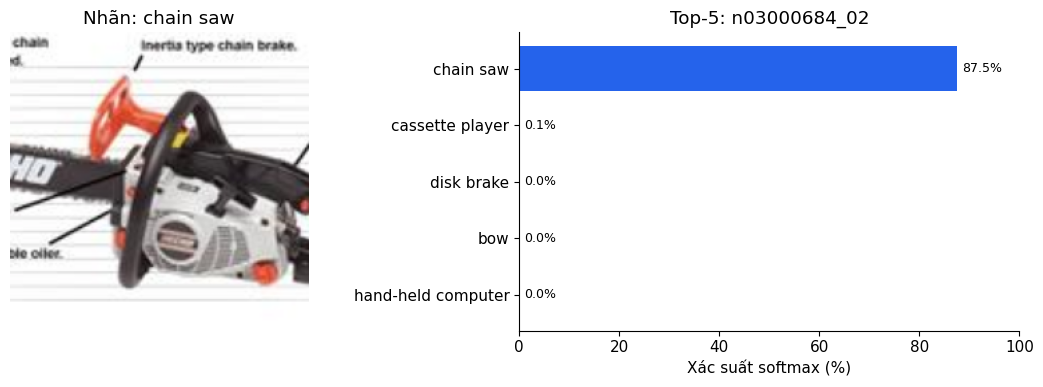

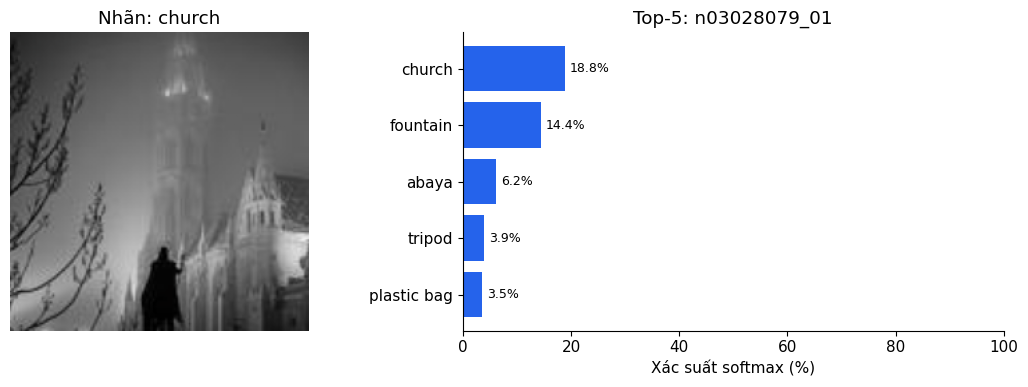

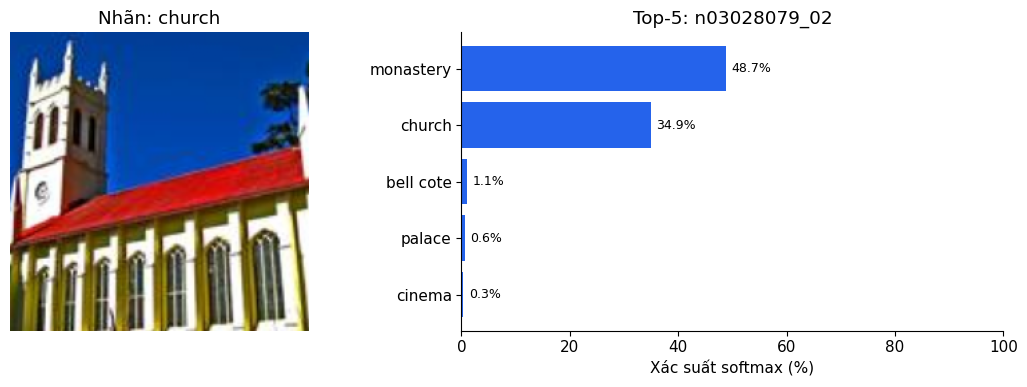

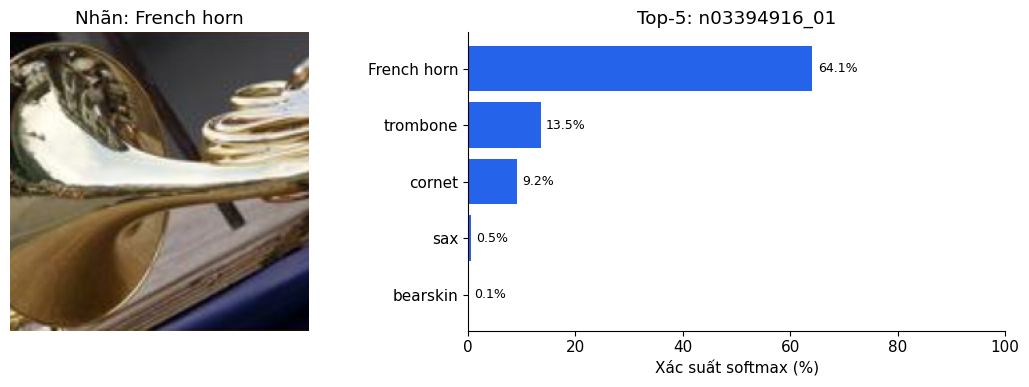

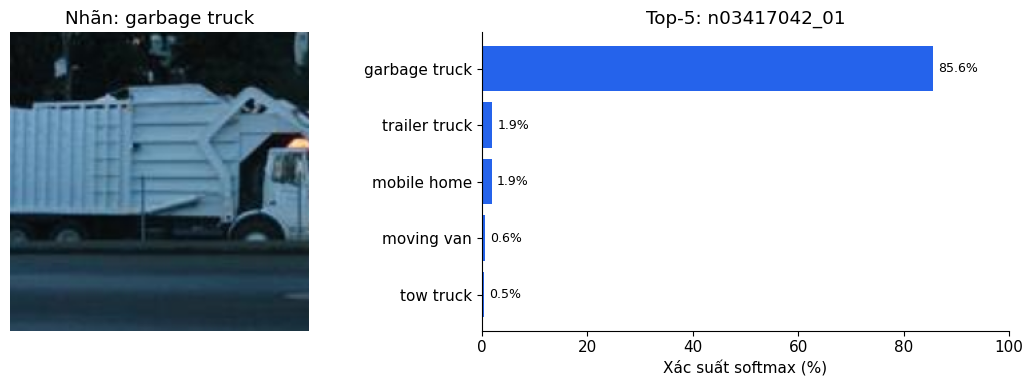

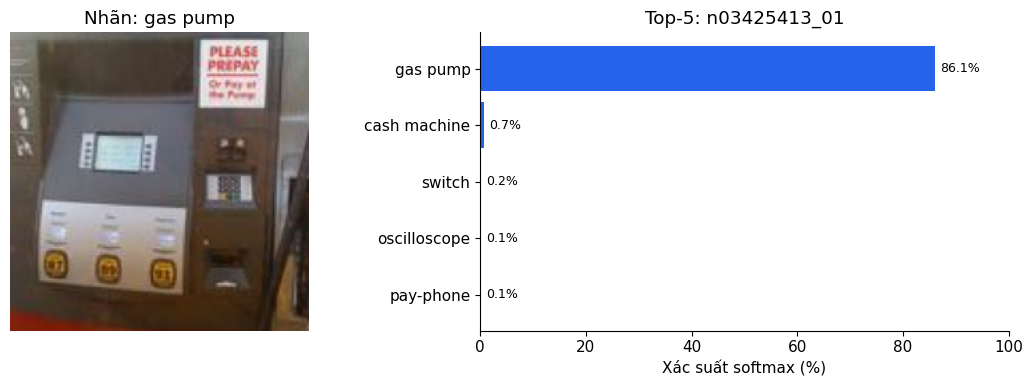

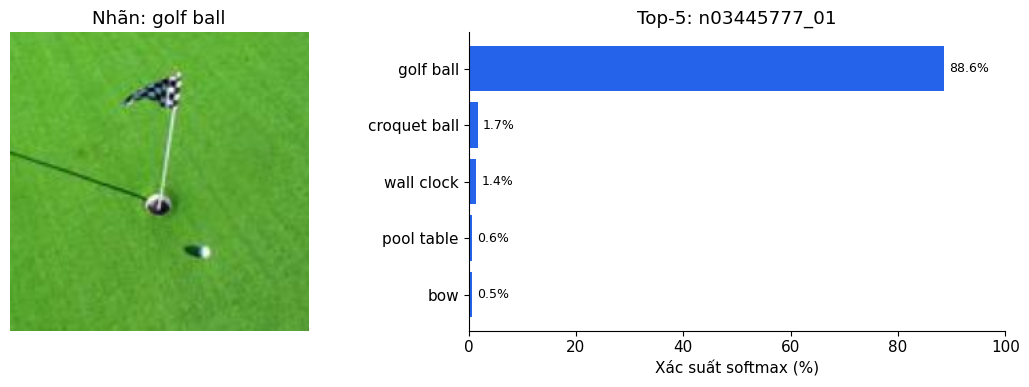

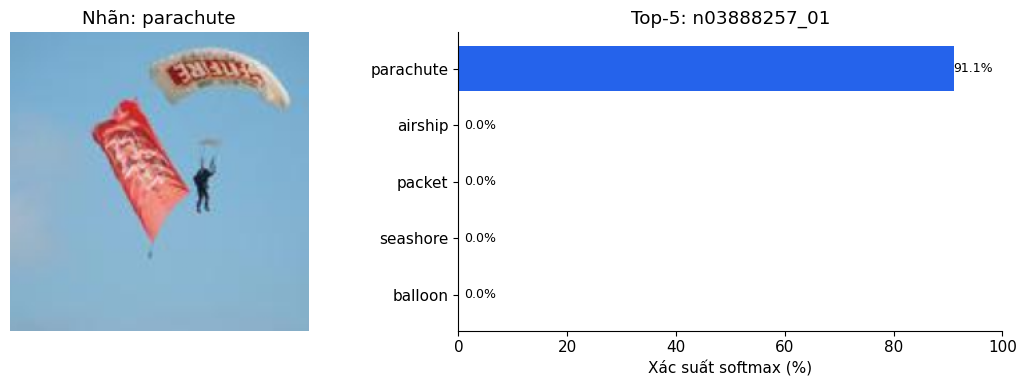

,image_id,true_class,top1,p_true,top1_correct,top5_correct
0,n01440764_01,tench,tench,0.907907,True,True
1,n01440764_02,tench,tench,0.893257,True,True
2,n02102040_01,English springer,English springer,0.695986,True,True
3,n02102040_02,English springer,English springer,0.805282,True,True
4,n02979186_01,cassette player,cassette player,0.454025,True,True
5,n02979186_02,cassette player,tape player,0.300924,False,True
6,n03000684_01,chain saw,chain saw,0.891775,True,True
7,n03000684_02,chain saw,chain saw,0.875101,True,True
8,n03028079_01,church,church,0.188424,True,True
9,n03028079_02,church,monastery,0.349031,False,True


,n_images,top1_count,top5_count,top1_rate,top5_rate
0,15,13,15,0.866667,1.0


**Các lỗi Top-1 quan sát được:** n02979186_02: nhãn cassette player, dự đoán tape player; n03028079_02: nhãn church, dự đoán monastery

,image_id,true_class,top1,p_true,top5_correct,"Giả thuyết, chưa xác minh"
5,n02979186_02,cassette player,tape player,0.300924,True,Các lớp thiết bị phát băng có hình dáng gần nhau
9,n03028079_02,church,monastery,0.349031,True,Kiến trúc church và monastery có đặc trưng thị...


In [8]:
@torch.inference_mode()
def infer(batch_tensors, batch_size=3):
    result=[]
    for start in range(0,len(batch_tensors),batch_size):
        result.append(model(torch.stack(batch_tensors[start:start+batch_size]).to(DEVICE)).softmax(-1).cpu())
    return torch.cat(result)
image_ids = manifest.image_id.tolist()
baseline = infer([tensors[key] for key in image_ids])
assert torch.isfinite(baseline).all()
torch.testing.assert_close(baseline.sum(-1),torch.ones(len(image_ids)),rtol=1e-5,atol=1e-6)
probabilities = dict(zip(image_ids,baseline))
predictions, summaries = [], []
def prediction_rows(image_id,variant,prob):
    values, indices = prob.topk(5)
    return [{'image_id':image_id,'variant':variant,'rank':rank,
             'class_id':int(idx),'class_name':categories[int(idx)],'probability':float(value)}
            for rank,(value,idx) in enumerate(zip(values,indices),1)]
for row in manifest.itertuples():
    prob=probabilities[row.image_id]
    predictions.extend(prediction_rows(row.image_id,'original',prob))
    indices=prob.topk(5).indices.tolist()
    summaries.append({'image_id':row.image_id,'true_class':row.class_name,
                      'top1':categories[indices[0]],'p_true':float(prob[row.class_id]),
                      'top1_correct':indices[0]==row.class_id,'top5_correct':row.class_id in indices})
    fig,axes=plt.subplots(1,2,figsize=(11,4),gridspec_kw={'width_ratios':[1,1.3]})
    axes[0].imshow(unnormalize(tensors[row.image_id])); axes[0].axis('off')
    axes[0].set_title(f'Nhãn: {row.class_name}')
    values=[float(prob[i])*100 for i in indices]
    axes[1].barh([categories[i] for i in indices][::-1],values[::-1],color=BLUE)
    axes[1].set_xlim(0,100); axes[1].set_xlabel('Xác suất softmax (%)')
    axes[1].set_title(f'Top-5: {row.image_id}')
    for j,value in enumerate(values[::-1]): axes[1].text(min(value+1,91),j,f'{value:.1f}%',va='center',fontsize=9)
    fig.tight_layout(); save_figure(fig,f'top5_{row.image_id}')
summary=pd.DataFrame(summaries)
export_table(summary,'baseline_summary','Kết quả trên 15 ảnh minh họa')
metrics={'n_images':len(summary),'top1_count':int(summary.top1_correct.sum()),
         'top5_count':int(summary.top5_correct.sum()),'top1_rate':float(summary.top1_correct.mean()),
         'top5_rate':float(summary.top5_correct.mean())}
export_table(pd.DataFrame([metrics]),'demo_metrics','Tỷ lệ đúng mô tả tập demo, không phải benchmark')
errors=summary.loc[~summary.top1_correct]
if len(errors):
    display(Markdown('**Các lỗi Top-1 quan sát được:** ' + '; '.join(f'{r.image_id}: nhãn {r.true_class}, dự đoán {r.top1}' for r in errors.itertuples())))
    error_details=errors[['image_id','true_class','top1','p_true','top5_correct']].copy()
    error_details['Giả thuyết, chưa xác minh'] = [
        'Các lớp thiết bị phát băng có hình dáng gần nhau' if r.true_class=='cassette player'
        else 'Kiến trúc church và monastery có đặc trưng thị giác tương tự' if r.true_class=='church'
        else 'Có thể chịu ảnh hưởng của crop, chi tiết hoặc ngữ cảnh' for r in errors.itertuples()]
    export_table(error_details,'error_analysis','Lỗi Top-1 và giả thuyết phân tích')
else:
    display(Markdown('**Không quan sát thấy lỗi Top-1 trên 15 ảnh gốc.** Mẫu nhỏ chưa chứng minh độ chính xác tổng quát.'))

## 6. Che vùng có kiểm soát
Chọn cố định ảnh đầu của ba lớp tench, English springer và cassette player,
độc lập với dự đoán. Trên ảnh **sau crop**, che từng cửa sổ 64×64 tại (0,0),
(80,80), (160,160). Tọa độ tính từ góc trái trên, bám lưới patch 16.
Che bằng 0 trên tensor chuẩn hóa, tương ứng mean RGB của transform.
Không crop hoặc chuẩn hóa lần thứ hai; không xóa token, L vẫn là 197.

So sánh cùng lớp nhãn thật: $\Delta p_{true}=p_{true,masked}-p_{true,original}$.
Bảng cũng theo dõi xác suất lớp Top-1 gốc, để tránh trừ xác suất hai lớp khác nhau.
Các vùng được gọi theo vị trí hình học; không giả định sẵn vùng đó là đối tượng hay nền.

,image_id,region,x,y,width,height,fill,true_class,top1_before,top1_after,p_true_before,p_true_after,delta_p_true,p_original_top1_before,p_original_top1_after,true_class_in_top5
0,n01440764_01,top_left,0,0,64,64,zero_normalized,tench,tench,tench,0.907907,0.841396,-0.066510,0.907907,0.841396,True
1,n01440764_01,center,80,80,64,64,zero_normalized,tench,tench,tench,0.907907,0.818239,-0.089668,0.907907,0.818239,True
2,n01440764_01,bottom_right,160,160,64,64,zero_normalized,tench,tench,tench,0.907907,0.821274,-0.086633,0.907907,0.821274,True
3,n02102040_01,top_left,0,0,64,64,zero_normalized,English springer,English springer,English springer,0.695986,0.655014,-0.040972,0.695986,0.655014,True
4,n02102040_01,center,80,80,64,64,zero_normalized,English springer,English springer,English springer,0.695986,0.522822,-0.173164,0.695986,0.522822,True
5,n02102040_01,bottom_right,160,160,64,64,zero_normalized,English springer,English springer,English springer,0.695986,0.613086,-0.082900,0.695986,0.613086,True
6,n02979186_01,top_left,0,0,64,64,zero_normalized,cassette player,cassette player,cassette player,0.454025,0.449533,-0.004492,0.454025,0.449533,True
7,n02979186_01,center,80,80,64,64,zero_normalized,cassette player,cassette player,cassette player,0.454025,0.463048,0.009023,0.454025,0.463048,True
8,n02979186_01,bottom_right,160,160,64,64,zero_normalized,cassette player,cassette player,cassette player,0.454025,0.470640,0.016614,0.454025,0.470640,True


,image_id,variant,rank,class_id,class_name,probability
0,n01440764_01,original,1,0,tench,0.907907
1,n01440764_01,original,2,389,barracouta,0.000727
2,n01440764_01,original,3,456,bow,0.000466
3,n01440764_01,original,4,766,rotisserie,0.000358
4,n01440764_01,original,5,758,reel,0.000356
...,...,...,...,...,...,...
115,n02979186_01,bottom_right,1,482,cassette player,0.470640
116,n02979186_01,bottom_right,2,848,tape player,0.326690
117,n02979186_01,bottom_right,3,485,CD player,0.030961
118,n02979186_01,bottom_right,4,481,cassette,0.018264


n01440764_01 (tench): p(nhãn thật) ban đầu 90.79%. Giá trị Δp nhỏ nhất trong ba vùng tại Trung tâm: 81.82%, Δp = -8.97 điểm phần trăm. Top-1: tench → tench. Kết luận chỉ áp dụng cho can thiệp này; vị trí và ngữ cảnh có thể ảnh hưởng kết quả.

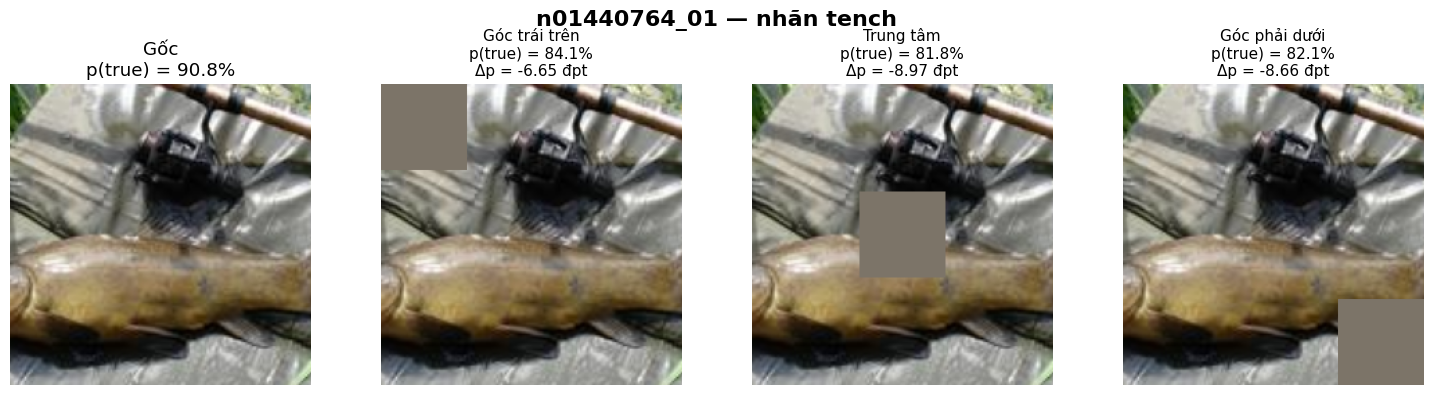

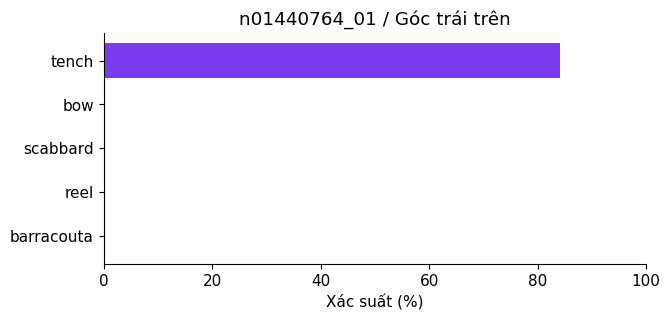

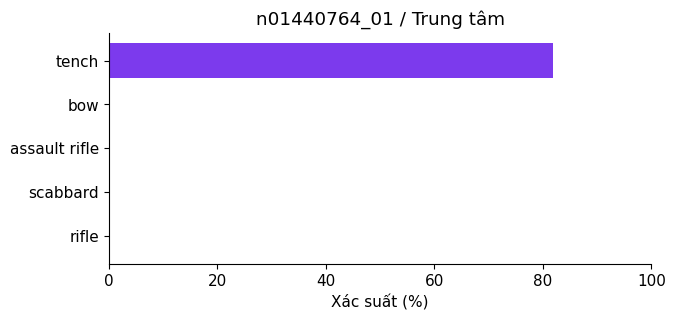

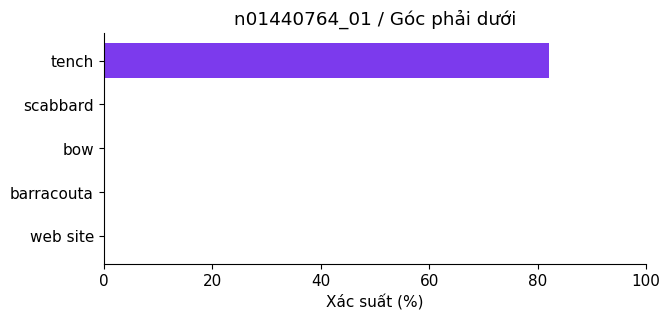

n02102040_01 (English springer): p(nhãn thật) ban đầu 69.60%. Giá trị Δp nhỏ nhất trong ba vùng tại Trung tâm: 52.28%, Δp = -17.32 điểm phần trăm. Top-1: English springer → English springer. Kết luận chỉ áp dụng cho can thiệp này; vị trí và ngữ cảnh có thể ảnh hưởng kết quả.

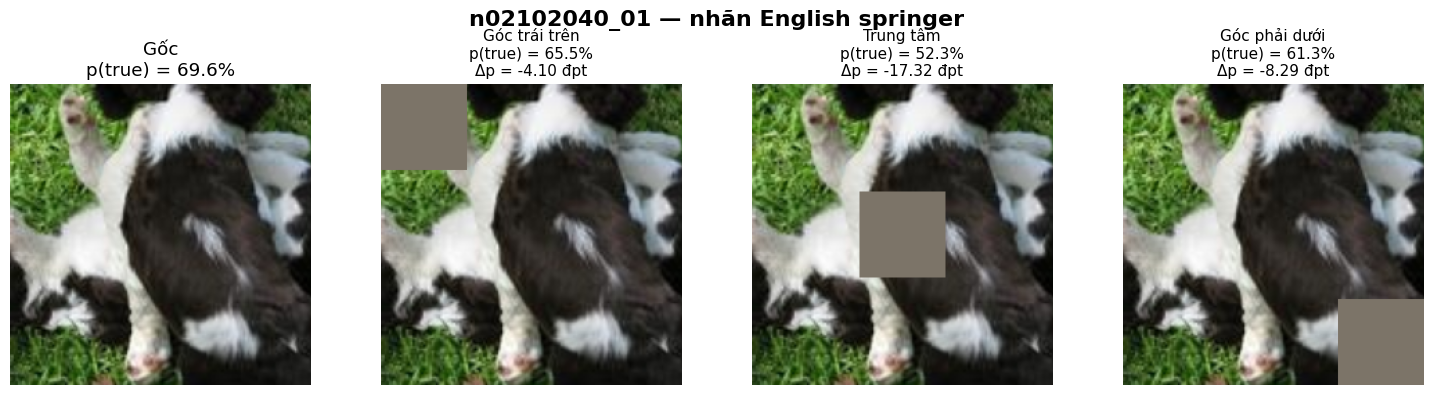

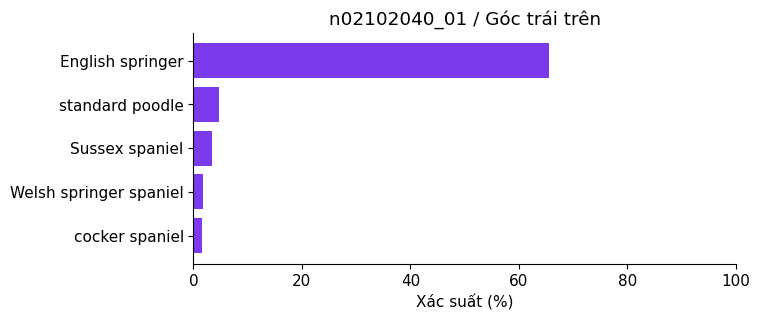

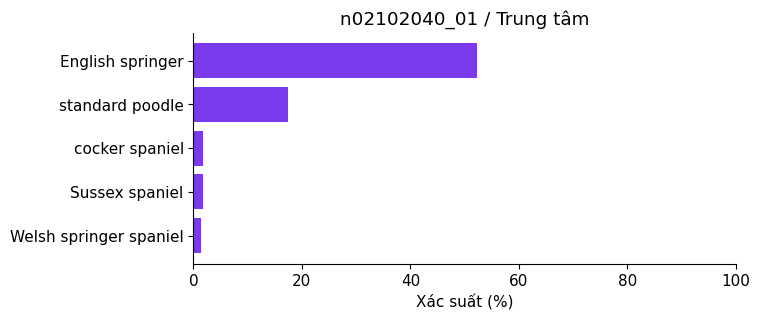

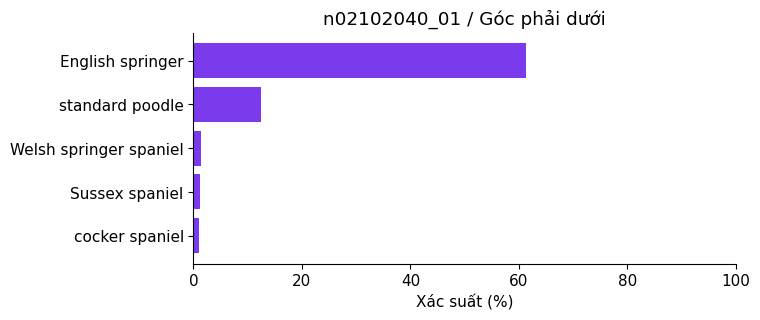

n02979186_01 (cassette player): p(nhãn thật) ban đầu 45.40%. Giá trị Δp nhỏ nhất trong ba vùng tại Góc trái trên: 44.95%, Δp = -0.45 điểm phần trăm. Top-1: cassette player → cassette player. Kết luận chỉ áp dụng cho can thiệp này; vị trí và ngữ cảnh có thể ảnh hưởng kết quả.

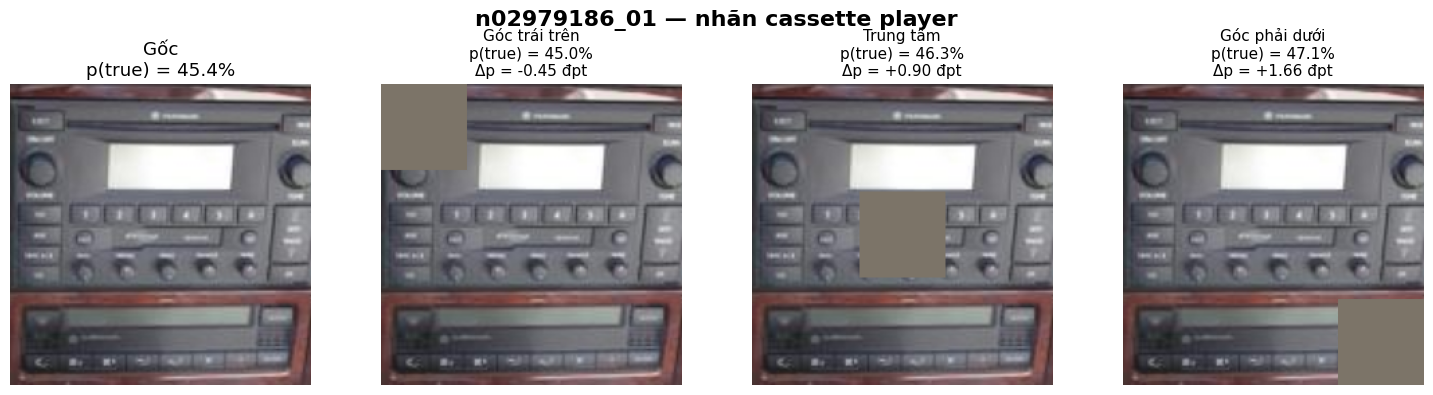

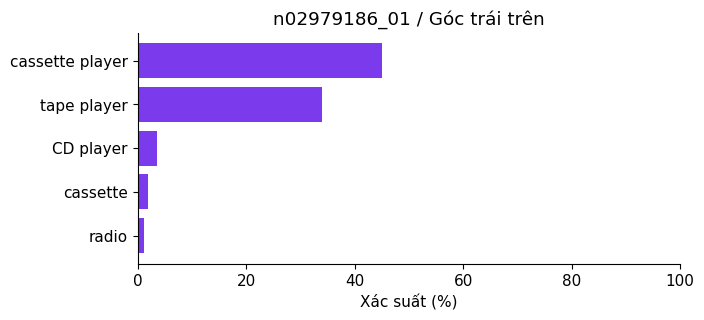

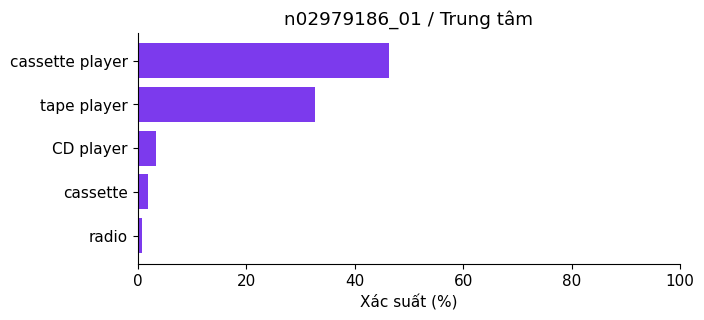

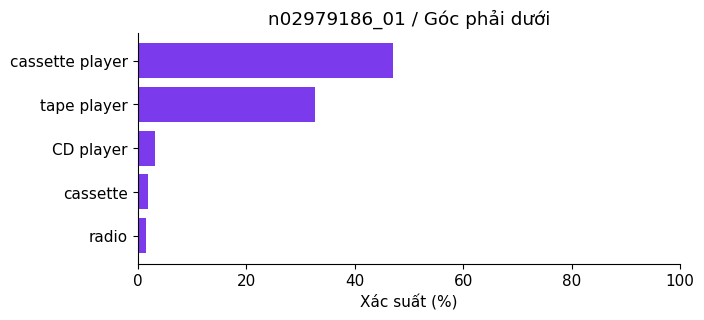

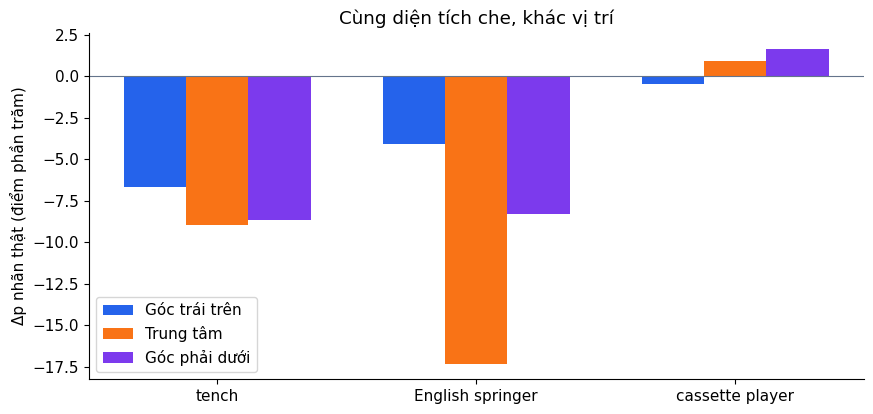

In [9]:
case_ids=[manifest.iloc[i].image_id for i in [0,2,4]]
regions={'top_left':(0,0,64,64),'center':(80,80,64,64),'bottom_right':(160,160,64,64)}
region_vi={'top_left':'Góc trái trên','center':'Trung tâm','bottom_right':'Góc phải dưới'}
masked_inputs,masked_meta=[],[]
for key in case_ids:
    for region,(rx,ry,rw,rh) in regions.items():
        masked=tensors[key].clone()
        masked[:,ry:ry+rh,rx:rx+rw]=0
        unchanged=torch.ones((224,224),dtype=torch.bool); unchanged[ry:ry+rh,rx:rx+rw]=False
        assert torch.equal(masked[:,unchanged],tensors[key][:,unchanged])
        masked_inputs.append(masked); masked_meta.append((key,region,rx,ry,rw,rh))
        save_rgb(masked,OUT/'occluded'/f'{key}_{region}.png')
masked_probs=infer(masked_inputs)
masked_lookup, occlusions={},[]
for meta,prob in zip(masked_meta,masked_probs):
    key,region,rx,ry,rw,rh=meta
    true_id=int(manifest.set_index('image_id').loc[key,'class_id'])
    original=probabilities[key]; original_top1=int(original.argmax())
    masked_lookup[(key,region)]=prob
    predictions.extend(prediction_rows(key,region,prob))
    occlusions.append(dict(image_id=key,region=region,x=rx,y=ry,width=rw,height=rh,
        fill='zero_normalized',true_class=categories[true_id],top1_before=categories[original_top1],
        top1_after=categories[int(prob.argmax())],p_true_before=float(original[true_id]),
        p_true_after=float(prob[true_id]),delta_p_true=float(prob[true_id]-original[true_id]),
        p_original_top1_before=float(original[original_top1]),p_original_top1_after=float(prob[original_top1]),
        true_class_in_top5=true_id in prob.topk(5).indices.tolist()))
occlusion=pd.DataFrame(occlusions)
export_table(occlusion,'occlusion_summary','Giao thức và kết quả che vùng',rows_per_page=9)
export_table(pd.DataFrame(predictions),'predictions','Top-5 cho ảnh gốc và mọi biến thể',rows_per_page=20)
analysis=[]
for key in case_ids:
    rows=occlusion[occlusion.image_id==key]
    true_name=rows.iloc[0].true_class
    most=rows.loc[rows.delta_p_true.idxmin()]
    text=(f'{key} ({true_name}): p(nhãn thật) ban đầu {most.p_true_before:.2%}. '
          f'Giá trị Δp nhỏ nhất trong ba vùng tại {region_vi[most.region]}: '
          f'{most.p_true_after:.2%}, Δp = {most.delta_p_true*100:+.2f} điểm phần trăm. '
          f'Top-1: {most.top1_before} → {most.top1_after}. '
          'Kết luận chỉ áp dụng cho can thiệp này; vị trí và ngữ cảnh có thể ảnh hưởng kết quả.')
    analysis.append({'image_id':key,'observation':text,'largest_drop_region':most.region})
    display(Markdown(text))
    fig,axes=plt.subplots(1,4,figsize=(15,4))
    axes[0].imshow(unnormalize(tensors[key])); axes[0].set_title(f'Gốc\np(true) = {most.p_true_before:.1%}')
    for ax,row in zip(axes[1:],rows.itertuples()):
        ax.imshow(Image.open(OUT/'occluded'/f'{key}_{row.region}.png'))
        ax.set_title(f'{region_vi[row.region]}\np(true) = {row.p_true_after:.1%}\nΔp = {row.delta_p_true*100:+.2f} đpt',fontsize=11)
    for ax in axes: ax.axis('off')
    fig.suptitle(f'{key} — nhãn {true_name}',fontsize=16,weight='bold')
    fig.tight_layout(); save_figure(fig,f'case_{key}')
    # Top-5 for each occluded variant is a separate exported chart.
    for region in regions:
        prob=masked_lookup[key,region]; vals,inds=prob.topk(5)
        fig,ax=plt.subplots(figsize=(7,3))
        ax.barh([categories[int(i)] for i in inds][::-1],vals.numpy()[::-1]*100,color=PURPLE)
        ax.set(xlim=(0,100),xlabel='Xác suất (%)',title=f'{key} / {region_vi[region]}')
        save_figure(fig,f'top5_{key}_{region}')
fig,ax=plt.subplots(figsize=(10,4.5))
for j,(region,label) in enumerate(region_vi.items()):
    vals=[float(occlusion[(occlusion.image_id==key)&(occlusion.region==region)].delta_p_true.iloc[0])*100 for key in case_ids]
    ax.bar(np.arange(3)+(j-1)*.24,vals,width=.24,label=label,color=[BLUE,ORANGE,PURPLE][j])
ax.set_xticks(np.arange(3),[manifest.set_index('image_id').loc[key,'class_name'] for key in case_ids])
ax.axhline(0,color='#64748B',linewidth=.8); ax.set_ylabel('Δp nhãn thật (điểm phần trăm)')
ax.legend(); ax.set_title('Cùng diện tích che, khác vị trí')
save_figure(fig,'occlusion_comparison')
(OUT/'case_analysis.json').write_text(json.dumps(analysis,ensure_ascii=False,indent=2),encoding='utf-8')
checks['occlusion_only_changes_selected_pixels']=True

## 7. ViT và CNN
So sánh dưới đây mô tả cơ chế, không phải phép đo tốc độ hay độ chính xác giữa hai mô hình.
CNN tích lũy ngữ cảnh khi receptive field mở rộng. ViT có attention toàn cục giữa
các token ngay trong một block, đồng thời vẫn chia sẻ trọng số projection/MLP giữa vị trí.

In [10]:
comparison=pd.DataFrame([
    ['Locality','Kernel cục bộ; ngữ cảnh mở rộng qua lớp','Attention toàn cục giữa token'],
    ['Chia sẻ trọng số','Kernel dùng chung trên không gian','Projection và MLP dùng chung trên token'],
    ['Inductive bias','Cấu trúc ưu tiên tính cục bộ và dịch chuyển','Ít ràng buộc 2D hơn; học quan hệ vị trí'],
    ['Dữ liệu','Thường có lợi khi dữ liệu hạn chế','Phụ thuộc dữ liệu, pretraining và regularization'],
    ['Tính toán','Phụ thuộc kernel, kênh và độ phân giải','Attention chuẩn theo L²; MLP theo L'],
    ['Lựa chọn','Đánh giá trên tác vụ và ngân sách thực tế','Không có kiến trúc luôn tốt hơn']
],columns=['Tiêu chí','CNN','ViT'])
export_table(comparison,'vit_cnn_comparison','So sánh cơ chế ViT và CNN')

,Tiêu chí,CNN,ViT
0,Locality,Kernel cục bộ; ngữ cảnh mở rộng qua lớp,Attention toàn cục giữa token
1,Chia sẻ trọng số,Kernel dùng chung trên không gian,Projection và MLP dùng chung trên token
2,Inductive bias,Cấu trúc ưu tiên tính cục bộ và dịch chuyển,Ít ràng buộc 2D hơn; học quan hệ vị trí
3,Dữ liệu,Thường có lợi khi dữ liệu hạn chế,"Phụ thuộc dữ liệu, pretraining và regularization"
4,Tính toán,"Phụ thuộc kernel, kênh và độ phân giải",Attention chuẩn theo L²; MLP theo L
5,Lựa chọn,Đánh giá trên tác vụ và ngân sách thực tế,Không có kiến trúc luôn tốt hơn


## 8. Kết luận và giới hạn
Ảnh trở thành 196 patch token, ghép CLS thành 197 token, giữ D=768 qua các encoder
rồi lấy CLS để phân loại. Trace và phép chiếu tương đương đã được kiểm tra bằng tensor thật.
Độ nhạy che vùng phụ thuộc vị trí và ảnh. Tô mean tạo can thiệp khác ảnh tự nhiên;
các thay đổi quan sát không tự chứng minh quan hệ nhân quả hoặc cách mô hình “hiểu” ảnh.
Tập 15 ảnh có phân bố lớp không đều và nguồn cùng họ ImageNet nên không suy rộng tỷ lệ đúng.
Xác suất softmax chưa được hiệu chỉnh. Không có thí nghiệm huấn luyện hay benchmark CNN.

**Nguồn:** [ViT paper](https://arxiv.org/abs/2010.11929),
[TorchVision model](https://docs.pytorch.org/vision/0.29/models/generated/torchvision.models.vit_b_16.html),
[TorchVision source](https://docs.pytorch.org/vision/0.29/_modules/torchvision/models/vision_transformer.html),
[Imagenette](https://github.com/fastai/imagenette).
Mã thí nghiệm trong notebook được viết cho dự án; kiến trúc/checkpoint dùng TorchVision.

In [11]:
checks['finite_normalized_probabilities']=bool(torch.isfinite(baseline).all())
checks['top5_rows_complete']=len(predictions)==(15+9)*5
checks['three_cases_three_regions']=len(occlusion)==9 and len(case_ids)==3
checks['all_trace_shapes_match']=all(row['Khớp'] for row in trace)
assert all(checks.values())
config={'executed_at':datetime.now(timezone(timedelta(hours=7))).isoformat(),
    'python':platform.python_version(),'torch':torch.__version__,'torchvision':torchvision.__version__,
    'numpy':np.__version__,'pandas':pd.__version__,'device':str(DEVICE),'threads':torch.get_num_threads(),
    'seed':SEED,'checkpoint':'ViT_B_16_Weights.IMAGENET1K_V1','checkpoint_sha256':checkpoint_hash,
    'transform':str(transform),'n_parameters':sum(p.numel() for p in model.parameters()),
    'n_blocks':len(model.encoder.layers),'heads':model.encoder.layers[0].num_heads,
    'hidden_dim':model.hidden_dim,'elapsed_seconds':round(time.perf_counter()-started,2),
    'data_count':15,'case_ids':case_ids,'occlusion_regions':regions,'checks':checks,'metrics':metrics}
(OUT/'run_config.json').write_text(json.dumps(config,ensure_ascii=False,indent=2),encoding='utf-8')
(OUT/'asset_manifest.json').write_text(json.dumps({'figures':figure_paths,'table_images':table_paths},indent=2),encoding='utf-8')
export_table(pd.DataFrame([{'Kiểm tra':k,'Đạt':v} for k,v in checks.items()]),'validation_checks','Kiểm tra thực nghiệm')
# Refresh after exporting the final check table.
(OUT/'asset_manifest.json').write_text(json.dumps({'figures':figure_paths,'table_images':table_paths},indent=2),encoding='utf-8')
print(f'Hoàn thành: {len(figure_paths)} hình, {len(table_paths)} ảnh bảng; thời gian {config["elapsed_seconds"]:.1f}s.')
print(f'Top-1: {metrics["top1_count"]}/15; Top-5: {metrics["top5_count"]}/15. Chỉ là tập minh họa.')

,Kiểm tra,Đạt
0,manifest_and_image_hashes,True
1,projection_equivalence,True
2,trace_matches_forward,True
3,occlusion_only_changes_selected_pixels,True
4,finite_normalized_probabilities,True
5,top5_rows_complete,True
6,three_cases_three_regions,True
7,all_trace_shapes_match,True


Hoàn thành: 33 hình, 18 ảnh bảng; thời gian 139.1s.
Top-1: 13/15; Top-5: 15/15. Chỉ là tập minh họa.
